In [2]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_fqe_final_seeds as fqe_ope

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [6]:
# --- run folders: fill in the two HS ones from your sweep notebook ---
cql_hs_dir   = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep"      # root of the HS CQL alpha sweep
# --- run folders: fill in the two HS ones from your sweep notebook ---
sarsa_hs_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds"      # root of the HS SARSA critics (seeds 0-4)
fqe_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/fqe/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds"      # root of the FQE critics (seeds 0-4)

# Session-only fallback; not needed once the runs.py edit is in
if "fqe" not in R.FAMILIES:
    R.register_family(R.FamilySpec(name="fqe", detect=R._path_contains("fqe")))

ALPHA = 0.0325
cql_study   = R.make_study(cql_hs_dir, family="cql", group_by=(),
                           include=lambda r: r.get("cql_alpha") is not None and abs(r.get("cql_alpha") - ALPHA) < 1e-9)
sarsa_study = R.make_study(sarsa_hs_dir, family="sarsa", group_by=())
fqe_study   = R.make_study(fqe_dir, family="fqe", group_by=())

cql_final    = M.load_study_models(cql_study)[()]       # {seed: LoadedModel}, alpha = 00.0325
sarsa_models = M.load_study_models(sarsa_study)          # {(): {seed: LoadedModel}}
fqe_models   = M.load_study_models(fqe_study)            # {(): {seed: LoadedModel}}

assert sorted(cql_final) == sorted(fqe_models[()]) == sorted(sarsa_models[()]) == [0, 1, 2, 3, 4], \
    (sorted(cql_final), sorted(fqe_models[()]), sorted(sarsa_models[()]))

store = D.DataStore(keep=("train", "val"))
print(fqe_study.table())

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/fqe/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: actor, critic)
  loaded LoadedModel(seed 1: actor, critic)
  loaded LoadedModel(seed 2: actor, critic)
  loaded LoadedModel(seed 3: actor, critic)
  loaded LoadedModel(seed 4: actor, critic)
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: c

In [8]:
ids = lambda s: {v.short() for v in s.data_identities().values()}
print(ids(fqe_study) <= ids(cql_study), ids(sarsa_study) <= ids(cql_study))   # same states per seed

sig = lambda s: dict(D.reward_signature(s.runs()[0]))
a = sig(cql_study)
for name, st in (("sarsa", sarsa_study), ("fqe", fqe_study)):
    b = sig(st)
    print(name, {k: (a.get(k), b.get(k)) for k in sorted(set(a) | set(b)) if a.get(k) != b.get(k)})

True True
sarsa {'make_rewards_positive': (None, 'False')}
fqe {'make_rewards_positive': (None, 'False')}


In [9]:
for seed, m in sorted(fqe_models[()].items()):
    print(seed, "|", m.record.data_identity.short())
    print("   target-policy hints:", fqe_ope.target_policy_hints(m))
    print("   discount/reward:", {k: m.record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})
print(sorted(fqe_models[()][0].record.hyperparams))

print("CQL :", {k: cql_final[0].record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})
print("SARSA:", {k: sarsa_models[()][0].record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})

0 | state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]
   target-policy hints: {}
   discount/reward: {'discount': 0.975, 'terminal_discount': 0.998, 'reward_type': 'health_score', 'health_score_scale': 0.0, 'health_score_hourly_change_scale': 1.0, 'total_health_score_scale': 1.0, 'terminal_reward_scale': 10.0, 'health_score_hourly_change_clip': 100.0, 'actions_shift': True}
1 | state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]
   target-policy hints: {}
   discount/reward: {'discount': 0.975, 'terminal_discount': 0.998, 'reward_type': 'health_score', 'health_score_scale': 0.0, 'health_score_hourly_change_scale': 1.0, 'total_health_score_scale': 1.0, 'terminal_reward_scale': 10.0, 'health_score_hourly_change_clip': 100.0, 'actions_shift': True}
2 | state seed 2, shared reward [mimic_iv_dynamic_

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: V_pi 0.23 [0.13, 0.35]  adv1 0.208  V_mu 0.26  dV -0.030 [-0.111, 0.047]  occupancy 0.982
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: V_pi 0.05 [-0.04, 0.15]  adv1 0.278  V_mu 0.08  dV -0.028 [-0.122, 0.074]  occupancy 0.973
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 2: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


... (3 outputs left out)

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 4: V_pi 0.97 [0.87, 1.07]  adv1 0.284  V_mu 0.91  dV 0.058 [-0.042, 0.161]  occupancy 0.975

Pairing (CQL seed <-> FQE seed):
 seed                                                                                                                                                                                                                                                                                                                                                     cql_run                                                                                                                                                                                                                                                                                                                      

,seed,alpha,n_rows,n_stays,V_pi,V_pi_lo,V_pi_hi,adv1,adv1_lo,adv1_hi,...,sarsa_adv_all_norm_lo,sarsa_adv_all_norm_hi,sarsa_frac_adv_pos,V_mu,V_mu_lo,V_mu_hi,dV,dV_lo,dV_hi,occupancy
0,0,0.032,220015,1256,0.233,0.126,0.346,0.208,0.187,0.229,...,0.127,0.161,0.573,0.263,0.135,0.384,-0.030,-0.111,0.047,0.982
1,1,0.032,220015,1256,0.055,-0.035,0.145,0.278,0.259,0.297,...,0.148,0.180,0.628,0.083,-0.049,0.214,-0.028,-0.122,0.074,0.973
2,2,0.032,220015,1256,2.628,2.505,2.756,0.303,0.280,0.323,...,0.149,0.185,0.608,0.187,0.071,0.286,2.441,2.318,2.568,0.975
3,3,0.032,220015,1256,2.395,2.286,2.497,0.289,0.270,0.308,...,0.124,0.154,0.606,-0.641,-0.763,-0.539,3.036,2.924,3.150,0.981
4,4,0.032,220015,1256,0.967,0.869,1.074,0.284,0.263,0.304,...,0.149,0.186,0.605,0.909,0.778,1.040,0.058,-0.042,0.161,0.975


,mean,min,max,std,seeds_with_CI_above_0
adv_all_norm,0.035,0.028,0.043,0.006,5.0
frac_adv_pos,0.563,0.525,0.587,0.023,NaN
sarsa_adv_all_norm,0.155,0.138,0.166,0.013,5.0
sarsa_frac_adv_pos,0.604,0.573,0.628,0.020,NaN
adv1,0.272,0.208,0.303,0.037,5.0
occupancy,0.977,0.973,0.982,0.004,NaN
V_pi,1.255,0.055,2.628,1.199,NaN
V_mu,0.160,-0.641,0.909,0.552,NaN
dV,1.095,-0.030,3.036,1.515,2.0


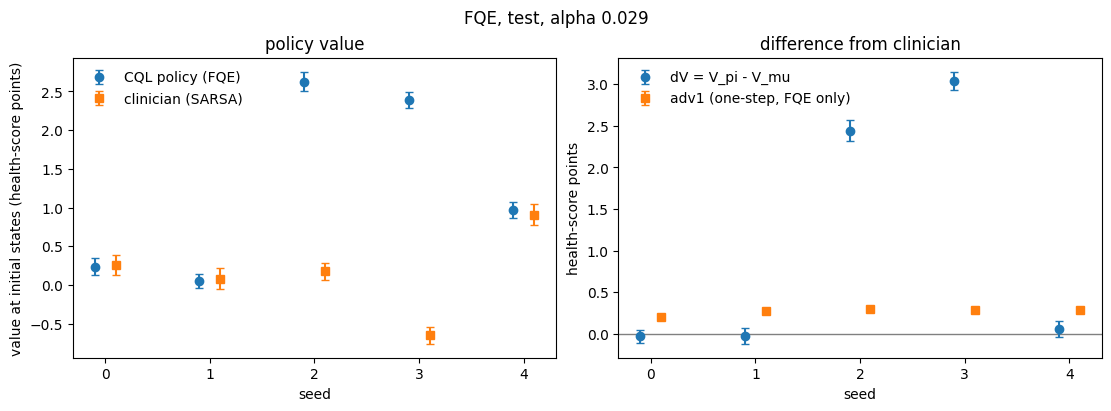

In [ ]:
store_test = D.DataStore(keep=("train", "test"))      # train for the occupancy table, test for the evaluation
ope_test = fqe_ope.run_fqe_ope(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                               split="test", n_severity_bins=200)
display(ope_test.round(3))
display(fqe_ope.summarize_fqe(ope_test).round(3))
fqe_ope.plot_fqe_ope(ope_test, title="FQE, test, alpha 0.0325");

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  seed 0: V_pi 0.23 [0.13, 0.35]  adv1 0.208  V_mu 0.26  dV -0.030 [-0.111, 0.047]  occupancy 0.982


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  seed 1: V_pi 0.05 [-0.04, 0.15]  adv1 0.278  V_mu 0.08  dV -0.028 [-0.122, 0.074]  occupancy 0.973


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 2: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  seed 2: V_pi 2.63 [2.50, 2.76]  adv1 0.303  V_mu 0.19  dV 2.441 [2.318, 2.568]  occupancy 0.975


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 3: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  seed 3: V_pi 2.39 [2.29, 2.50]  adv1 0.289  V_mu -0.64  dV 3.036 [2.924, 3.150]  occupancy 0.981


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


  seed 4: V_pi 0.97 [0.87, 1.07]  adv1 0.284  V_mu 0.91  dV 0.058 [-0.042, 0.161]  occupancy 0.975

Pairing (CQL seed <-> FQE seed):
 seed                                                                                                                                                                                                                                                                                                                                                     cql_run                                                                                                                                                                                                                                                                                                                            fqe_run fqe_target_hint                                                 check reward_diffs
    0 /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined

,mean,min,max,std,seeds_with_CI_above_0
adv_all_norm,0.035,0.028,0.043,0.006,5.0
frac_adv_pos,0.563,0.525,0.587,0.023,NaN
sarsa_adv_all_norm,0.155,0.138,0.166,0.013,5.0
sarsa_frac_adv_pos,0.604,0.573,0.628,0.020,NaN
adv1,0.272,0.208,0.303,0.037,5.0
occupancy,0.977,0.973,0.982,0.004,NaN
V_pi,1.255,0.055,2.628,1.199,NaN
V_mu,0.160,-0.641,0.909,0.552,NaN
dV,1.095,-0.030,3.036,1.515,2.0


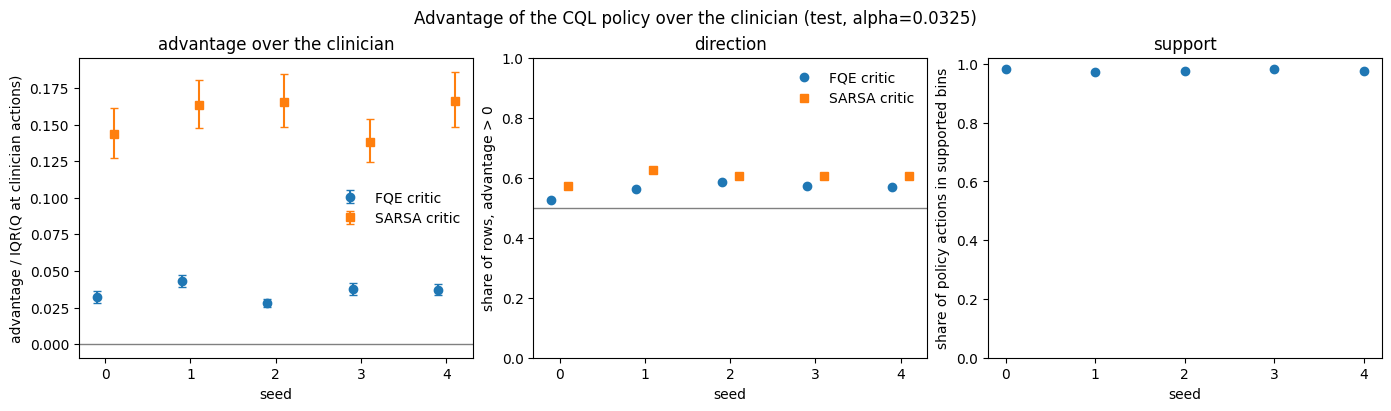

In [14]:
df_test = fqe_ope.run_fqe_ope(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                              split="test", n_severity_bins=200)
display(fqe_ope.summarize_fqe(df_test).round(3))
fig = fqe_ope.plot_fqe_advantage(df_test, title="Advantage of the CQL policy over the clinician (test, alpha=0.0325)")

In [18]:
rows = []
for k in sorted(cql_final):
    m = cql_final[k]; p = store_test.processor(m, "test")
    s, a = D.states(p), D.actions(p)
    api = fqe_ope.actor_actions(m, s)
    f, sa = fqe_models[()][k], sarsa_models[()][k]
    adv_f = f.q(s, api, scaled=True) - f.q(s, a, scaled=True)
    adv_s = sa.q(s, api, scaled=True) - sa.q(s, a, scaled=True)
    dfl, dva = api[:, 0] - a[:, 0], api[:, 1] - a[:, 1]
    rows.append({"seed": k,
        "frac_pos_fqe": (adv_f > 0).mean(), "frac_pos_sarsa": (adv_s > 0).mean(),
        "sign_agree": (np.sign(adv_f) == np.sign(adv_s)).mean(), "corr_adv": np.corrcoef(adv_f, adv_s)[0, 1],
        "frac_pi_more_fluid": (dfl > 1e-4).mean(), "frac_pi_less_fluid": (dfl < -1e-4).mean(),
        "frac_pi_more_vaso": (dva > 1e-4).mean(), "frac_pi_less_vaso": (dva < -1e-4).mean(),
        "vaso_fire_clin": (a[:, 1] > 1e-4).mean(), "vaso_fire_pi": (api[:, 1] > 1e-4).mean(),
        "frac_same_action": ((np.abs(dfl) < 1e-4) & (np.abs(dva) < 1e-4)).mean(),
        "corr_adv_fluiddiff_fqe": np.corrcoef(adv_f, dfl)[0, 1], "corr_adv_fluiddiff_sarsa": np.corrcoef(adv_s, dfl)[0, 1],
        "corr_adv_vasodiff_fqe": np.corrcoef(adv_f, dva)[0, 1], "corr_adv_vasodiff_sarsa": np.corrcoef(adv_s, dva)[0, 1]})
display(pd.DataFrame(rows).round(3))

,seed,frac_pos_fqe,frac_pos_sarsa,sign_agree,corr_adv,frac_pi_more_fluid,frac_pi_less_fluid,frac_pi_more_vaso,frac_pi_less_vaso,vaso_fire_clin,vaso_fire_pi,frac_same_action,corr_adv_fluiddiff_fqe,corr_adv_fluiddiff_sarsa,corr_adv_vasodiff_fqe,corr_adv_vasodiff_sarsa
0,0,0.525,0.573,0.821,0.842,0.605,0.361,0.072,0.176,0.193,0.201,0.034,-0.071,-0.018,-0.414,-0.535
1,1,0.562,0.628,0.795,0.873,0.546,0.390,0.057,0.176,0.193,0.179,0.063,-0.080,0.034,-0.465,-0.567
2,2,0.587,0.608,0.801,0.799,0.576,0.409,0.057,0.178,0.193,0.170,0.014,-0.056,-0.024,-0.371,-0.567
3,3,0.574,0.606,0.792,0.800,0.574,0.399,0.054,0.179,0.193,0.178,0.026,-0.023,-0.034,-0.408,-0.612
4,4,0.569,0.605,0.814,0.850,0.573,0.394,0.059,0.177,0.193,0.187,0.033,-0.007,-0.015,-0.375,-0.567


In [19]:
rows = []
for k in sorted(cql_final):
    m = cql_final[k]; p = store_test.processor(m, "test")
    s, a = D.states(p), D.actions(p)
    api = fqe_ope.actor_actions(m, s)
    f, sa = fqe_models[()][k], sarsa_models[()][k]
    adv_f = f.q(s, api, scaled=True) - f.q(s, a, scaled=True)
    adv_s = sa.q(s, api, scaled=True) - sa.q(s, a, scaled=True)
    dva = api[:, 1] - a[:, 1]
    for name, mask in (("less_vaso", dva < -1e-4), ("same_vaso", np.abs(dva) <= 1e-4), ("more_vaso", dva > 1e-4)):
        rows.append({"seed": k, "group": name, "frac_rows": mask.mean(),
                     "mean_adv_fqe": adv_f[mask].mean(), "mean_adv_sarsa": adv_s[mask].mean(),
                     "contrib_fqe": adv_f[mask].sum() / len(adv_f), "contrib_sarsa": adv_s[mask].sum() / len(adv_s)})
display(pd.DataFrame(rows).round(3))

,seed,group,frac_rows,mean_adv_fqe,mean_adv_sarsa,contrib_fqe,contrib_sarsa
0,0,less_vaso,0.176,0.095,0.427,0.017,0.075
1,0,same_vaso,0.752,0.003,0.015,0.003,0.011
2,0,more_vaso,0.072,-0.009,-0.079,-0.001,-0.006
3,1,less_vaso,0.176,0.116,0.552,0.020,0.097
4,1,same_vaso,0.767,0.010,0.031,0.008,0.024
5,1,more_vaso,0.057,-0.010,-0.059,-0.001,-0.003
6,2,less_vaso,0.178,0.101,0.548,0.018,0.098
7,2,same_vaso,0.765,0.011,0.030,0.009,0.023
8,2,more_vaso,0.057,0.008,-0.093,0.000,-0.005
9,3,less_vaso,0.179,0.103,0.509,0.018,0.091


In [20]:
rows = []
for k in sorted(cql_final):
    m = cql_final[k]; p = store_test.processor(m, "test")
    s, a = D.states(p), D.actions(p)
    api = fqe_ope.actor_actions(m, s)
    f, sa = fqe_models[()][k], sarsa_models[()][k]
    hs, _ = D.health_score(p)
    sev = D.severity_bin(hs, D.severity_edges(hs, 5))      # bin 0 = sickest
    dva = api[:, 1] - a[:, 1]
    rows.append(pd.DataFrame({"seed": k, "sev": sev, "less_vaso": dva < -1e-4,
                              "adv_fqe": f.q(s, api, scaled=True) - f.q(s, a, scaled=True),
                              "adv_sarsa": sa.q(s, api, scaled=True) - sa.q(s, a, scaled=True)}))
d = pd.concat(rows)
display(d.groupby("sev").agg(frac_less_vaso=("less_vaso", "mean"), adv_fqe=("adv_fqe", "mean"), adv_sarsa=("adv_sarsa", "mean")).round(3))

,frac_less_vaso,adv_fqe,adv_sarsa
sev,,,
0,0.380,0.036,0.177
1,0.240,0.027,0.119
2,0.139,0.021,0.088
3,0.083,0.021,0.084
4,0.044,0.017,0.050


  seed 0 fqe: policy 0.032  shuffle_global 0.023  shuffle_within_severity 0.027
  seed 0 sarsa: policy 0.143  shuffle_global 0.097  shuffle_within_severity 0.107
  seed 1 fqe: policy 0.043  shuffle_global 0.025  shuffle_within_severity 0.034
  seed 1 sarsa: policy 0.163  shuffle_global 0.099  shuffle_within_severity 0.113
  seed 2 fqe: policy 0.028  shuffle_global 0.022  shuffle_within_severity 0.028
  seed 2 sarsa: policy 0.166  shuffle_global 0.105  shuffle_within_severity 0.123
  seed 3 fqe: policy 0.038  shuffle_global 0.026  shuffle_within_severity 0.034
  seed 3 sarsa: policy 0.138  shuffle_global 0.100  shuffle_within_severity 0.110
  seed 4 fqe: policy 0.037  shuffle_global 0.034  shuffle_within_severity 0.042
  seed 4 sarsa: policy 0.166  shuffle_global 0.143  shuffle_within_severity 0.154


,seed,critic,control,adv_norm,lo,hi,p_ge_policy
0,0,fqe,policy,0.032,NaN,NaN,NaN
1,0,fqe,shuffle_global,0.023,0.023,0.023,0.00
2,0,fqe,shuffle_within_severity,0.027,0.027,0.027,0.00
3,0,sarsa,policy,0.143,NaN,NaN,NaN
4,0,sarsa,shuffle_global,0.097,0.096,0.099,0.00
5,0,sarsa,shuffle_within_severity,0.107,0.106,0.109,0.00
6,1,fqe,policy,0.043,NaN,NaN,NaN
7,1,fqe,shuffle_global,0.025,0.024,0.025,0.00
8,1,fqe,shuffle_within_severity,0.034,0.034,0.035,0.00
9,1,sarsa,policy,0.163,NaN,NaN,NaN


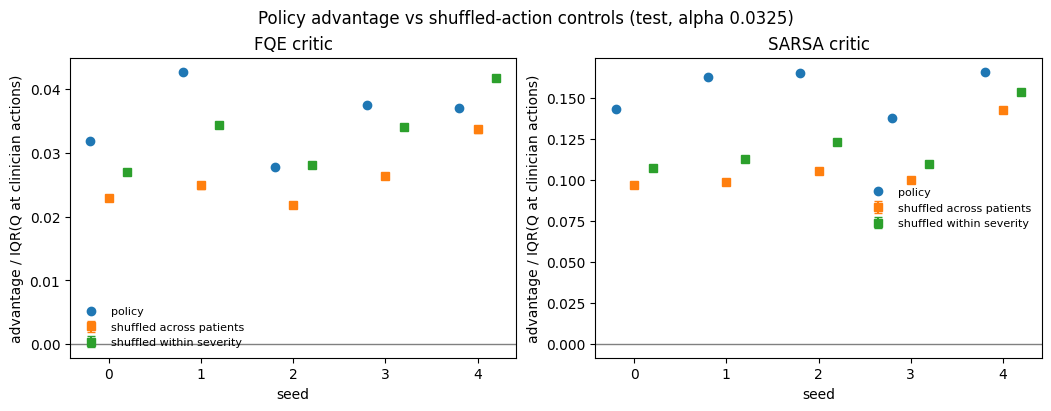

In [17]:
shuf = fqe_ope.shuffled_policy_advantage(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                                         split="test", n_perm=100)
display(shuf.round(3))
fqe_ope.plot_shuffle_control(shuf, title="Policy advantage vs shuffled-action controls (test, alpha 0.0325)");

# FQE off-policy evaluation of the final CQL policy (alpha = 0.0325, with actions, test split)

## Setup
- Final CQL models (alpha = 0.0325, selected on val), 5 seeds, health-score reward, states with actions.
- Test split: 220,015 patient-hours, 1,256 stays per seed.
- Pairing: CQL seed k <-> FQE seed k (target policy: CQL seed k's actor) <-> SARSA seed k (clinician continuation), all on DeepHit seed k.
- Checks passed: seed and state embedding; discount and reward settings (CQL = FQE = SARSA).
- **Not verified:** FQE runs record no target-policy path, so "FQE seed k was fit to CQL seed k" is assumed. Confirm from the training log.
- Advantage = Q(s, pi(s)) - Q(s, a_clin), mean over rows, normalised by the IQR of Q at clinician actions.
- CIs are 95% bootstrap over stays (one seed); the spread across seeds is training variability.
- Occupancy = share of actions in (severity[200 bins] x fluid[10] x vaso[10]) cells with >= 10 training rows.

## Results (mean across 5 seeds, range in brackets)
- Normalised advantage, FQE: 0.035 [0.028, 0.043]; SARSA: 0.155 [0.138, 0.166]. CIs exclude 0 in 5/5 seeds for both critics.
- Rows where pi's action is rated higher than the clinician's: FQE 56% [53, 59]; SARSA 60% [57, 63].
- Sign agreement between critics 79-82%; correlation of per-row advantages 0.80-0.87.
- Occupancy 97.7% [97.3, 98.2].
- One-step FQE advantage at initial states (adv1): 0.27 health-score points [0.21, 0.30], 5/5 CIs above 0.
- Policy-value difference dV = V_pi - V_mu: -0.03, -0.03, +2.44, +3.04, +0.06 (CI above 0 in 2/5). Not consistent across seeds, so not used as evidence.
- Policy vs clinician actions: more fluid in 55-61% of rows, less in 36-41%, same action in 1-6%. Vaso fire rate 17-20% (clinician 19.3%); less vaso in ~18% of rows, more in ~6%.

## Controls
- Shuffling pi's actions across patient-hours retains 58-92% (FQE) / 61-86% (SARSA) of the advantage.
- Shuffling within severity bins retains 79-114% (FQE) / 69-93% (SARSA). Under FQE the within-severity shuffle matches or exceeds the policy in seeds 2 and 4.
- The per-row advantage correlates with the vaso change (FQE -0.37 to -0.47, SARSA -0.54 to -0.61) and not with the fluid change (|r| < 0.1).
- Rows where pi gives less vaso carry 67-89% (FQE) / 82-94% (SARSA) of the total advantage. Rows where pi gives more vaso carry ~0 / slightly negative.
- By severity (quintile 0 = sickest): share of rows with less vaso 38%, 24%, 14%, 8%, 4%; mean advantage FQE 0.036, 0.027, 0.021, 0.021, 0.017; SARSA 0.177, 0.119, 0.088, 0.084, 0.050.

## Interpretation
- The advantage is positive under both critics, in every seed, but modest.
- It mostly reflects the doses pi uses (notably lower vaso, concentrated in the sickest patients) and not which patient gets which dose.
- Both critics are trained on the same observational data, so a learned preference for lower vaso may reflect confounding by indication and not benefit.

## Caveats / to do
- Verify the FQE target-policy pairing (see Setup).
- Monte Carlo calibration of the SARSA clinician baseline (V_mu vs observed return) and dV_mc not yet run.
- Diagnostics (shuffle control, vaso decomposition) were run on test; no selection decisions were based on them.
- The advantage is a one-step quantity, not a difference in policy values.

Paper text (results paragraph)

We evaluated the final CQL policy (α = 0.0325, chosen on the validation split) on the held-out test split (220,015 patient-hours from 1,256 stays) using fitted Q evaluation (FQE), with a SARSA critic as an independent estimate of the continuation under clinician behaviour. For each patient-hour we computed the advantage Q(s, π(s)) − Q(s, a_clin), normalised by the interquartile range of Q at clinician actions. Uncertainty from patient sampling was estimated by bootstrapping stays, and training variability is shown by the range across five seeds.

The mean normalised advantage was positive under both critics (FQE 0.035, range 0.028–0.043; SARSA 0.155, range 0.138–0.166), with bootstrap intervals excluding zero in all five seeds, and 97.7% of the policy’s actions fell in cells supported by at least 10 training observations. The effect was modest. The policy’s action was rated above the clinician’s in 56% (FQE) and 60% (SARSA) of patient-hours, and the two critics agreed on its sign in about 80%. The policy-value difference at initial states was inconsistent across seeds (intervals excluded zero in two of five), so we do not base conclusions on it.

Control analyses indicated that the advantage reflects what the policy recommends more than for whom. Randomly reassigning its actions across patient-hours retained 58–92% (FQE) and 61–86% (SARSA) of the advantage, and reassigning within severity bins retained 79–114% and 69–93%. Most of the advantage came from the roughly 18% of patient-hours in which the policy recommended a lower vasopressor dose than the clinician (67–89% of the total under FQE, 82–94% under SARSA), concentrated in the sickest patients (38% of patient-hours in the lowest health-score quintile versus 4% in the highest), while changes to fluid dosing alone contributed little. Because both critics were fitted to the same observational data, a learned preference for lower vasopressor doses may reflect confounding by indication, and the estimated advantage should not be interpreted as evidence of improved outcomes.

Two notes before this goes in the paper:

FQE target-policy pairing: it is still unverified (the grep cell I gave you). If you can’t confirm it, add a sentence to the methods saying the pairing is by seed.
dV sentence: I left out the explanation for the inconsistent dV. If the Monte Carlo calibration later shows critic level offsets, you can add “attributable to level differences between separately trained critics”, but I haven’t tested that.

# monte carlo

  seed 0: V_mu 0.263  observed G0 -0.844  bias +1.107 [+0.487, +1.682]  interior (H=119) gap +0.472 [+0.280, +0.675]  corr(interior) 0.04  dV_mc 1.077 [0.456, 1.652]
  seed 1: V_mu 0.083  observed G0 -0.844  bias +0.927 [+0.284, +1.497]  interior (H=119) gap +0.325 [+0.133, +0.531]  corr(interior) 0.07  dV_mc 0.898 [0.270, 1.480]
  seed 2: V_mu 0.187  observed G0 -0.844  bias +1.031 [+0.380, +1.610]  interior (H=119) gap +0.144 [-0.054, +0.345]  corr(interior) 0.08  dV_mc 3.471 [2.823, 4.085]
  seed 3: V_mu -0.641  observed G0 -0.844  bias +0.203 [-0.411, +0.774]  interior (H=119) gap -0.069 [-0.260, +0.122]  corr(interior) 0.10  dV_mc 3.239 [2.599, 3.842]
  seed 4: V_mu 0.909  observed G0 -0.844  bias +1.753 [+1.117, +2.336]  interior (H=119) gap +0.951 [+0.755, +1.150]  corr(interior) 0.03  dV_mc 1.811 [1.167, 2.398]


,seed,n_stays,V_mu,G0,G0_lo,G0_hi,bias,bias_lo,bias_hi,corr_stay,corr_all,V_pi,dV_mc,dV_mc_lo,dV_mc_hi
0,0,1256,0.263,-0.844,-1.443,-0.189,1.107,0.487,1.682,0.285,0.138,0.233,1.077,0.456,1.652
1,1,1256,0.083,-0.844,-1.443,-0.189,0.927,0.284,1.497,0.268,0.163,0.055,0.898,0.270,1.480
2,2,1256,0.187,-0.844,-1.443,-0.189,1.031,0.380,1.610,0.217,0.153,2.628,3.471,2.823,4.085
3,3,1256,-0.641,-0.844,-1.443,-0.189,0.203,-0.411,0.774,0.263,0.163,2.395,3.239,2.599,3.842
4,4,1256,0.909,-0.844,-1.443,-0.189,1.753,1.117,2.336,0.255,0.146,0.967,1.811,1.167,2.398


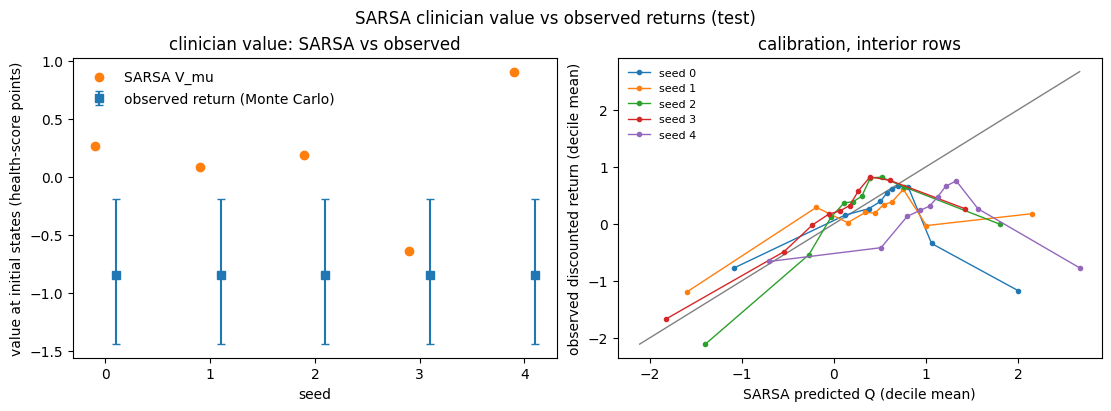

In [22]:
mc_df, mc_calib = fqe_ope.run_mc_calibration(
    sarsa_models, store_test, split="test",
    cql_models=cql_final, fqe_models=fqe_models, n_boot=1000)

display(mc_df[["seed", "n_stays", "V_mu", "G0", "G0_lo", "G0_hi", "bias", "bias_lo", "bias_hi",
               "corr_stay", "corr_all", "V_pi", "dV_mc", "dV_mc_lo", "dV_mc_hi"]].round(3))
fig = fqe_ope.plot_mc_calibration(mc_df, mc_calib, title="SARSA clinician value vs observed returns (test)")

## Monte Carlo calibration of the SARSA clinician value (test)
- Observed mean discounted return of logged stays G0 = -0.84 [-1.44, -0.19].
- SARSA overestimates it at initial states: bias +0.20 to +1.75 health-score points (CI above 0 in 4/5 seeds); interior-row gap -0.07 to +0.95.
- Q correlates weakly with observed return (interior rows 0.03-0.10; initial states 0.22-0.29).
- dV_mc = V_pi - G0 is positive in 5/5 seeds, but dV_mc = dV + bias exactly: it mostly reflects critic bias, so absolute policy values and value differences from the TD critics are not used as evidence of improvement.

The SARSA critic overestimated the clinician policy’s value relative to observed returns (by 0.2 to 1.8 health-score points at initial states), and its predictions correlated only weakly with observed returns; we therefore do not report policy-value differences from the learned critics and restrict inference to within-critic advantages.

In [24]:
print(mc_df[["seed", "gamma", "V_mu", "G0", "Q_all_mean", "G_all_mean", "corr_all"]].round(3))
display(mc_calib[mc_calib.bin >= 8].round(3))    # decile calibration, seed 0

# same check on the TRAINING split: if the bias is there too, it is systematic (reward/discount/underfit), not generalisation
store_tr = D.DataStore(keep=("train",))
mc_tr, calib_tr = fqe_ope.run_mc_calibration(sarsa_models, store_tr, split="train", n_boot=200)
print(mc_tr[["seed", "V_mu", "G0", "bias", "Q_all_mean", "G_all_mean", "corr_all"]].round(3))

   seed  gamma   V_mu     G0  Q_all_mean  G_all_mean  corr_all
0     0  0.975  0.263 -0.844       0.657       0.186     0.138
1     1  0.975  0.083 -0.844       0.449       0.186     0.163
2     2  0.975  0.187 -0.844       0.202       0.186     0.153
3     3  0.975 -0.641 -0.844       0.057       0.186     0.163
4     4  0.975  0.909 -0.844       1.051       0.186     0.146


,seed,bin,n,Q_pred,G_obs
8,0,8,10991,1.060,-0.345
9,0,9,10991,1.997,-1.169
18,1,8,10991,1.003,-0.031
19,1,9,10991,2.146,0.177
28,2,8,10991,0.760,0.649
29,2,9,10991,1.808,-0.011
38,3,8,10991,0.610,0.760
39,3,9,10991,1.421,0.266
48,4,8,10991,1.564,0.263
49,4,9,10991,2.667,-0.772


  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: V_mu 0.257  observed G0 -0.112  bias +0.369 [+0.047, +0.734]  interior (H=119) gap +0.446 [+0.367, +0.535]  corr(interior) 0.05
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: V_mu 0.014  observed G0 -0.112  bias +0.126 [-0.222, +0.469]  

In [25]:
rows = []
for k in sorted(cql_final):
    m = cql_final[k]; p = store_test.processor(m, "test")
    s, a = D.states(p), D.actions(p)
    api = fqe_ope.actor_actions(m, s)
    f, sa = fqe_models[()][k], sarsa_models[()][k]
    q_s = sa.q(s, a, scaled=True)
    keep = q_s < np.quantile(q_s, 0.9)
    for name, c in (("fqe", f), ("sarsa", sa)):
        q_cl = c.q(s, a, scaled=True); adv = c.q(s, api, scaled=True) - q_cl
        iqr = np.quantile(q_cl, 0.75) - np.quantile(q_cl, 0.25)
        rows.append({"seed": k, "critic": name, "adv_norm_all": adv.mean() / iqr, "adv_norm_excl_top": adv[keep].mean() / iqr,
                     "frac_pos_all": (adv > 0).mean(), "frac_pos_excl": (adv[keep] > 0).mean()})
display(pd.DataFrame(rows).round(3))

,seed,critic,adv_norm_all,adv_norm_excl_top,frac_pos_all,frac_pos_excl
0,0,fqe,0.032,0.034,0.525,0.533
1,0,sarsa,0.143,0.151,0.573,0.584
2,1,fqe,0.043,0.045,0.562,0.569
3,1,sarsa,0.163,0.166,0.628,0.639
4,2,fqe,0.028,0.029,0.587,0.595
5,2,sarsa,0.166,0.170,0.608,0.618
6,3,fqe,0.038,0.041,0.574,0.585
7,3,sarsa,0.138,0.149,0.606,0.621
8,4,fqe,0.037,0.040,0.569,0.578
9,4,sarsa,0.166,0.174,0.605,0.618


- Robustness to the miscalibrated tail: excluding the top decile of SARSA value at clinician actions leaves the advantage unchanged (FQE 0.028-0.043 -> 0.029-0.045; SARSA 0.138-0.166 -> 0.149-0.174; share of rows with positive advantage +0.7 to +1.5 points).

In [7]:
def td_diag(sarsa, p):
    gamma = float(sarsa.record.get("discount"))
    s, a, s2, a2 = D.states(p), D.actions(p), D.next_states(p), D.next_actions(p)
    r, done = D.rewards(p) / sarsa.reward_scale, D.dones(p)
    q, q2 = sarsa.q(s, a, scaled=True), sarsa.q(s2, a2, scaled=True)
    td = r + gamma * (~done) * q2 - q               # target - prediction; ~0 on average if Q fits these rewards
    return {"seed": sarsa.seed, "mean_reward": r.mean(), "mean_td": td.mean(),
            "mean_td_nondone": td[~done].mean(), "mean_td_done": td[done].mean(),
            "rmse_td": np.sqrt((td ** 2).mean()), "n_done": int(done.sum())}

sar = sarsa_models[()]
p_tr = {s: store_tr.processor(cql_final[s], "train") for s in sar}
display(pd.DataFrame([td_diag(sar[s], p_tr[s]) for s in sorted(sar)]).round(4))

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL da

,seed,mean_reward,mean_td,mean_td_nondone,mean_td_done,rmse_td,n_done
0,0,0.015,0.0161,0.0157,0.1767,0.6012,1036
1,1,0.015,0.0172,0.0166,0.2401,0.6146,1036
2,2,0.015,0.0145,0.0141,0.1589,0.6112,1036
3,3,0.015,0.0147,0.0144,0.1545,0.6157,1036
4,4,0.015,0.0155,0.0150,0.1952,0.6077,1036
